# DATA ANALYTICS ML CHALLENGE / 2026-2
## Semana 14. PCA, regresión logística regularizada, costos empresariales y prueba Kolmogorov-Smirnov

Universidad Central · Caso: *Brazilian E-Commerce Public Dataset by Olist* · Estudiante ID 13

---

## 1. Introducción

**Problema de negocio.** Olist conecta vendedores con compradores en Brasil. Cuando un pedido llega **después** de la fecha estimada que se prometió al cliente, la experiencia empeora. Si pudiéramos anticipar qué pedidos tienen más riesgo de llegar tarde (con la información disponible al momento de la compra), la empresa podría actuar antes: avisar al cliente, revisar al vendedor o ajustar el plazo prometido.

**De dónde venimos.**

* **Semana 12:** construimos una muestra reproducible de 35.000 pedidos (una fila por pedido), definimos la variable objetivo `is_late` (1 = llegó después de la fecha estimada) y entrenamos una regresión logística con `class_weight='balanced'`. Ese modelo es nuestro **modelo base** (modelo A de hoy).
* **Semana 13:** reducción de dimensionalidad. La idea central es que muchas variables numéricas están correlacionadas entre sí y se pueden resumir en pocas *componentes principales* (PCA), que se calculan con la descomposición en valores singulares (SVD).
* **Semana 14 (este notebook):** comprobamos con experimentos si resumir las variables numéricas con PCA ayuda, cómo cambia el resultado al modificar la regularización `C`, cuánto costarían los errores del modelo en dinero y si la variable `valor_flete` se comporta parecido en entrenamiento y validación (prueba KS).

> **Continuidad.** Se usa la **misma muestra** de 35.000 pedidos (semilla `1013`) y las **mismas particiones** 24.500 / 5.250 / 5.250 de la semana 12. La partición de **prueba** queda reservada: en este notebook no se usa para entrenar ni para elegir modelos.

## 2. Objetivos

1. Recuperar exactamente la muestra y las particiones de la semana 12 y verificar que son las mismas (huella de la muestra).
2. Aplicar **PCA** a las variables numéricas conservando al menos el **90 %** de la varianza explicada, y graficar la varianza acumulada.
3. Entrenar y comparar **cuatro regresiones logísticas** (A: sin PCA, C=1; B: PCA, C=1; C: PCA, C=0,1; D: PCA, C=10) con Accuracy, Precision, Recall, F1 y Average Precision en validación, con umbral 0,50.
4. Calcular **verdaderos/falsos positivos y negativos** y el **costo empresarial** (FP = R$ 8, FN = R$ 35, supuestos didácticos), y justificar qué modelo conviene.
5. Aplicar la **prueba de Kolmogorov-Smirnov** a `valor_flete` (entrenamiento vs. validación) e interpretarla con cuidado.

## 3. Librerías y parámetros

Se importan las librerías y se fijan los parámetros del experimento en un solo lugar para que sean fáciles de ubicar y no queden "números mágicos" dentro del código.

In [1]:
import hashlib
import json
import sys
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy
import sklearn
from IPython.display import Markdown, display
from scipy.stats import ks_2samp
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import PCA
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, average_precision_score,
                             confusion_matrix)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Con ciertas combinaciones de scipy y scikit-learn aparece un aviso inofensivo
# ("Unknown solver options") al entrenar la regresión logística. No afecta el
# resultado; se silencia solo ese mensaje para no ocultar otros avisos.
warnings.filterwarnings('ignore', message='Unknown solver options')

# ---- Parámetros del experimento (todos en un solo lugar) -------------------
ID_ESTUDIANTE = 13            # mismo ID que en la semana 12
SEMILLA = 1000 + ID_ESTUDIANTE  # semilla de la semana 12 (1013)
UMBRAL = 0.50                 # umbral de clasificación fijo para los 4 modelos
VARIANZA_OBJETIVO = 0.90      # PCA: conservar al menos 90 % de la varianza
COSTO_FP = 8                  # R$ por falso positivo (supuesto didáctico)
COSTO_FN = 35                 # R$ por falso negativo (supuesto didáctico)
ALFA = 0.05                   # nivel de significancia de la prueba KS

# ---- Rutas: funciona si se ejecuta desde la raíz del repo o desde notebooks/
RAIZ = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
RUTA_REPORTES = RAIZ / 'reports'
RUTA_FIGURAS = RUTA_REPORTES / 'figures'
RUTA_FIGURAS.mkdir(parents=True, exist_ok=True)

print('Raíz del proyecto:', RAIZ)
print('Python', sys.version.split()[0], '| pandas', pd.__version__, '| numpy', np.__version__,
      '| scikit-learn', sklearn.__version__, '| scipy', scipy.__version__)

Raíz del proyecto: /home/claude/DA_olist-ml-challenge-C3-main
Python 3.12.3 | pandas 2.2.3 | numpy 2.5.4 | scikit-learn 1.6.1 | scipy 1.18.1


## 4. Preparación de datos

Esta sección **repite fielmente la preparación de la semana 12** (mismas tablas, mismas agregaciones, mismos filtros) para que el notebook sea ejecutable por sí solo, sin depender de variables de otra sesión.

Dos ideas clave:

* **Una fila por pedido.** Un pedido puede tener varios productos y varios pagos. Si uniéramos las tablas sin resumirlas, un mismo pedido aparecería repetido y el modelo "vería" más veces a los pedidos grandes. Por eso `items` y `pagos` se resumen primero por `order_id` (sumas, máximos, conteos) y después se unen; el `assert` comprueba que no quedaron duplicados.
* **Variable objetivo `is_late`.** Vale 1 si la fecha real de entrega fue posterior a la fecha estimada, y 0 en caso contrario. Solo se usan pedidos **entregados** con fechas completas y coherentes.

Los datos se descargan de una versión **fijada por commit** del conjunto público de Olist; no se guardan en el repositorio.

In [2]:
ORIGEN = ('https://raw.githubusercontent.com/spdrio/'
          'Brazilian-E-Commerce-Public-Dataset-by-Olist/'
          'fa0cc6d1aff713d3c8b9a1e633b56889881848bf/files')

pedidos = pd.read_csv(f'{ORIGEN}/olist_orders_dataset.csv')
items = pd.read_csv(f'{ORIGEN}/olist_order_items_dataset.csv')
productos = pd.read_csv(f'{ORIGEN}/olist_products_dataset.csv')
clientes = pd.read_csv(f'{ORIGEN}/olist_customers_dataset.csv')
vendedores = pd.read_csv(f'{ORIGEN}/olist_sellers_dataset.csv')
pagos = pd.read_csv(f'{ORIGEN}/olist_order_payments_dataset.csv')
categorias = pd.read_csv(f'{ORIGEN}/product_category_name_translation.csv')

print('Pedidos:', pedidos.shape)
print('Items:', items.shape)
print('Productos:', productos.shape)
print('Clientes:', clientes.shape)
print('Vendedores:', vendedores.shape)
print('Pagos:', pagos.shape)

Pedidos: (99441, 8)
Items: (112650, 7)
Productos: (32951, 9)
Clientes: (99441, 5)
Vendedores: (3095, 4)
Pagos: (103886, 5)


In [3]:
# --- Resumen de productos y vendedores: una fila por pedido -----------------
items = items.merge(productos, on='product_id', how='left', validate='many_to_one')
items = items.merge(vendedores, on='seller_id', how='left', validate='many_to_one')
items = items.merge(categorias, on='product_category_name',
                    how='left', validate='many_to_one')

items['volumen_cm3'] = (items['product_length_cm'] * items['product_height_cm']
                       * items['product_width_cm'])
items['categoria'] = items['product_category_name_english'].fillna(
    items['product_category_name']).fillna('sin_categoria')

resumen_items = items.groupby('order_id', as_index=False).agg(
    valor_productos=('price', 'sum'),
    valor_flete=('freight_value', 'sum'),
    precio_maximo=('price', 'max'),
    cantidad_items=('order_item_id', 'count'),
    cantidad_productos=('product_id', 'nunique'),
    cantidad_vendedores=('seller_id', 'nunique'),
    peso_total_g=('product_weight_g', 'sum'),
    peso_maximo_g=('product_weight_g', 'max'),
    volumen_total_cm3=('volumen_cm3', 'sum'),
    fotos_promedio=('product_photos_qty', 'mean'),
    descripcion_promedio=('product_description_lenght', 'mean'),
    nombre_promedio=('product_name_lenght', 'mean'),
)

# Categoría y vendedor del producto de mayor precio del pedido.
principal = (items.sort_values(['order_id', 'price', 'order_item_id'],
                                ascending=[True, False, True])
             .drop_duplicates('order_id'))
principal = principal[['order_id', 'categoria', 'seller_state', 'seller_city']]
principal = principal.rename(columns={
    'categoria': 'categoria_principal',
    'seller_state': 'estado_vendedor',
    'seller_city': 'ciudad_vendedor'
})

# --- Resumen de pagos: una fila por pedido ----------------------------------
resumen_pagos = pagos.groupby('order_id', as_index=False).agg(
    numero_pagos=('payment_sequential', 'count'),
    cuotas_maximas=('payment_installments', 'max'),
    valor_pagado=('payment_value', 'sum'),
)
pago_principal = (pagos.sort_values(['order_id', 'payment_value'],
                                    ascending=[True, False])
                  .drop_duplicates('order_id'))
pago_principal = pago_principal[['order_id', 'payment_type']].rename(
    columns={'payment_type': 'tipo_pago_principal'})

# --- Integración de las tablas ----------------------------------------------
data = pedidos.merge(clientes[['customer_id', 'customer_state', 'customer_city']],
                     on='customer_id', how='inner', validate='one_to_one')
data = data.merge(resumen_items, on='order_id', how='inner', validate='one_to_one')
data = data.merge(principal, on='order_id', how='left', validate='one_to_one')
data = data.merge(resumen_pagos, on='order_id', how='left', validate='one_to_one')
data = data.merge(pago_principal, on='order_id', how='left', validate='one_to_one')

assert data['order_id'].is_unique, 'Hay pedidos duplicados después de las uniones.'
print('Pedidos integrados:', len(data))

Pedidos integrados: 98666


In [4]:
# --- Variable objetivo y variables derivadas --------------------------------
fechas = ['order_purchase_timestamp', 'order_estimated_delivery_date',
          'order_delivered_customer_date']
for columna in fechas:
    data[columna] = pd.to_datetime(data[columna], errors='coerce')

# Solo pedidos entregados con fechas completas y coherentes.
data = data.loc[data['order_status'] == 'delivered'].dropna(subset=fechas).copy()
compra = data['order_purchase_timestamp'].dt.normalize()
prevista = data['order_estimated_delivery_date'].dt.normalize()
real = data['order_delivered_customer_date'].dt.normalize()

data['dias_prometidos'] = (prevista - compra).dt.days
data['dias_entrega'] = (real - compra).dt.days        # solo se usa para filtrar, NO es predictor
data['is_late'] = (real > prevista).astype(int)       # variable objetivo
data['mes_compra'] = compra.dt.month
data['dia_semana_compra'] = compra.dt.dayofweek
data['dia_mes_compra'] = compra.dt.day
data['hora_compra'] = data['order_purchase_timestamp'].dt.hour
data['compra_fin_semana'] = (data['dia_semana_compra'] >= 5).astype(int)

data['vendedor_mismo_estado'] = (
    data['customer_state'] == data['estado_vendedor']).astype(int)
data['vendedor_misma_ciudad'] = (
    data['vendedor_mismo_estado'].eq(1) &
    data['customer_city'].str.lower().eq(data['ciudad_vendedor'].str.lower())
).astype(int)
data['proporcion_flete'] = data['valor_flete'] / (
    data['valor_productos'] + data['valor_flete']).replace(0, np.nan)

data = data.loc[(data['dias_prometidos'] >= 0) &
                (data['dias_entrega'] >= 0)].copy()
data = data.sort_values('order_id').reset_index(drop=True)

print('Pedidos disponibles:', len(data))
print('Entregas tardías:', round(100 * data['is_late'].mean(), 2), '%')

Pedidos disponibles: 96470
Entregas tardías: 6.77 %


### Variables del modelo

* **Variable objetivo (lo que queremos predecir):** `is_late`.
* **Variables predictoras (lo que el modelo usa para predecir):** 24 numéricas y 4 categóricas, todas conocidas al cerrar la compra (plazo prometido, calendario, contenido y dimensiones del pedido, ubicación, medio de pago).
* **Prevención de fuga de información (*data leakage*):** la fecha real de entrega, `dias_entrega`, el estado del pedido y las reseñas posteriores **no** son predictoras, porque solo se conocen después de la entrega y le "regalarían" la respuesta al modelo.

In [5]:
columnas_numericas = [
    'dias_prometidos', 'mes_compra', 'dia_semana_compra',
    'dia_mes_compra', 'hora_compra', 'compra_fin_semana',
    'valor_productos', 'valor_flete', 'precio_maximo',
    'cantidad_items', 'cantidad_productos', 'cantidad_vendedores',
    'peso_total_g', 'peso_maximo_g', 'volumen_total_cm3',
    'fotos_promedio', 'descripcion_promedio', 'nombre_promedio',
    'numero_pagos', 'cuotas_maximas', 'valor_pagado',
    'vendedor_mismo_estado', 'vendedor_misma_ciudad', 'proporcion_flete'
]
columnas_categoricas = [
    'customer_state', 'estado_vendedor',
    'categoria_principal', 'tipo_pago_principal'
]
columnas = columnas_numericas + columnas_categoricas

# Ninguna variable que solo se conoce tras la entrega puede ser predictora.
prohibidas = {'is_late', 'dias_entrega', 'order_delivered_customer_date', 'order_status'}
assert prohibidas.isdisjoint(columnas), 'Hay variables con fuga de información.'
assert data['order_id'].is_unique
assert len(data) >= 35000
print('Variables predictoras:', len(columnas))
print('Numéricas:', len(columnas_numericas), '| Categóricas:', len(columnas_categoricas))

Variables predictoras: 28
Numéricas: 24 | Categóricas: 4


## 5. Recuperación de la muestra y de las particiones

El ID `13` genera siempre la misma semilla (`1013`) y por tanto **la misma muestra y las mismas particiones** que en la semana 12. El código es idéntico al de esa semana. Para comprobarlo, se calcula la **huella** de la muestra (un resumen `sha256` de la lista de `order_id`) y se compara con la guardada en `reports/S12_resultados_ID_13.json`.

* **Entrenamiento (24.500):** el modelo aprende aquí. Todo el preprocesamiento (imputación, escalado, PCA, One-Hot) se **ajusta solo con estos datos**.
* **Validación (5.250):** se usa para comparar configuraciones y tomar decisiones.
* **Prueba (5.250):** queda **reservada**; en este notebook no se usa.

In [6]:
muestra, _ = train_test_split(data, train_size=35000,
                             random_state=SEMILLA, stratify=data['is_late'])
muestra = muestra.sort_values('order_id').reset_index(drop=True)

train, temporal = train_test_split(muestra, test_size=0.30,
                                  random_state=SEMILLA, stratify=muestra['is_late'])
valid, test = train_test_split(temporal, test_size=0.50,
                              random_state=SEMILLA, stratify=temporal['is_late'])

X_train, y_train = train[columnas], train['is_late']
X_valid, y_valid = valid[columnas], valid['is_late']
# 'test' NO se usa en ningún cálculo de este notebook (partición reservada).

huella_muestra = hashlib.sha256('|'.join(muestra['order_id']).encode()).hexdigest()[:12]
print('Semilla:', SEMILLA, '| Huella de muestra:', huella_muestra)
print('Muestra:', len(muestra), '| Train:', len(train), '| Valid:', len(valid), '| Test:', len(test))
print('Tasa de entregas tardías -> train: %.4f | valid: %.4f | test: %.4f'
      % (y_train.mean(), y_valid.mean(), test['is_late'].mean()))

# --- Continuidad con la semana 12 ------------------------------------------
ruta_s12 = RUTA_REPORTES / 'S12_resultados_ID_13.json'
s12 = None
if ruta_s12.exists():
    s12 = json.loads(ruta_s12.read_text(encoding='utf-8'))
    assert s12['semilla'] == SEMILLA, 'La semilla no coincide con la semana 12.'
    assert (s12['n_muestra'], s12['n_train'], s12['n_valid'], s12['n_test']) == (
        len(muestra), len(train), len(valid), len(test)), 'Los tamaños no coinciden con S12.'
    assert s12['huella_muestra'] == huella_muestra, 'La muestra NO es la de la semana 12.'
    print('Continuidad verificada: misma semilla, mismos tamaños y misma huella que S12.')
else:
    print('Aviso: no se encontró', ruta_s12.name, '- no se pudo comparar con S12.')

Semilla: 1013 | Huella de muestra: 7c40e95d5d35
Muestra: 35000 | Train: 24500 | Valid: 5250 | Test: 5250
Tasa de entregas tardías -> train: 0.0678 | valid: 0.0678 | test: 0.0676
Continuidad verificada: misma semilla, mismos tamaños y misma huella que S12.


## 6. PCA sobre las variables numéricas

### Idea en palabras simples

Tenemos 24 variables numéricas, y varias se mueven juntas (por ejemplo, peso total, volumen y valor del flete). **PCA** busca nuevas "variables resumen", llamadas **componentes principales**, que:

1. son combinaciones de las variables originales,
2. no están correlacionadas entre sí, y
3. están ordenadas: la primera captura la mayor parte posible de la variación de los datos, la segunda la mayor parte de lo que queda, y así sucesivamente.

La **varianza explicada** de una componente es la fracción de la variación total que esa componente captura. La **varianza explicada acumulada** suma las fracciones de las primeras *k* componentes: indica cuánta información (variación) conservamos si nos quedamos solo con *k* componentes.

### Relación con SVD

PCA se calcula con la **descomposición en valores singulares (SVD)**. Si $Z$ es la matriz de datos estandarizada (cada columna con media 0), entonces $Z = U\,\Sigma\,V^T$. Las filas de $V^T$ son las direcciones de las componentes y la varianza que explica cada componente es $\sigma_i^2/(n-1)$, donde $\sigma_i$ son los valores singulares. Más abajo se comprueba numéricamente.

### Reglas que se respetan

* PCA se aplica **solo a las variables numéricas**; las categóricas siguen con su procesamiento (imputación + One-Hot).
* Imputación, escalado y PCA se **ajustan solo con entrenamiento**. Validación solo se *transforma* con lo aprendido.
* PCA exige variables en la misma escala; por eso se estandarizan antes.

> **Advertencia conceptual:** PCA es *no supervisado*: ordena las componentes por la **variación** que capturan, no por su utilidad para predecir `is_late`. Una componente que varía poco podría, en teoría, ser predictiva.

In [7]:
# Preprocesamiento numérico (se ajusta SOLO con entrenamiento).
pre_numerico = make_pipeline(SimpleImputer(strategy='median'), StandardScaler())
Z_train = pre_numerico.fit_transform(X_train[columnas_numericas])

# PCA completa (todas las componentes) para estudiar la varianza.
pca_completa = PCA(svd_solver='full', random_state=SEMILLA).fit(Z_train)
var_explicada = pca_completa.explained_variance_ratio_
var_acumulada = np.cumsum(var_explicada)

# Menor número de componentes cuya varianza acumulada es >= 90 %.
n_componentes_90 = int(np.argmax(var_acumulada >= VARIANZA_OBJETIVO)) + 1

# Verificación: PCA(n_components=0.90) de scikit-learn elige el mismo número.
assert PCA(n_components=VARIANZA_OBJETIVO, svd_solver='full',
           random_state=SEMILLA).fit(Z_train).n_components_ == n_componentes_90

tabla_pca = pd.DataFrame({
    'componente': [f'PC{i}' for i in range(1, len(var_explicada) + 1)],
    'varianza_explicada': var_explicada,
    'varianza_acumulada': var_acumulada,
})
display(tabla_pca.round(4))
print(f'Variables numéricas originales: {Z_train.shape[1]}')
print(f'Componentes necesarias para >= {VARIANZA_OBJETIVO:.0%}: {n_componentes_90} '
      f'(varianza acumulada = {var_acumulada[n_componentes_90 - 1]:.4f})')
print(f'Con {n_componentes_90 - 1} componentes solo se llega a {var_acumulada[n_componentes_90 - 2]:.4f}')

,componente,varianza_explicada,varianza_acumulada
0,PC1,0.1881,0.1881
1,PC2,0.0959,0.2840
2,PC3,0.0775,0.3615
3,PC4,0.0752,0.4367
4,PC5,0.0726,0.5093
5,PC6,0.0508,0.5602
6,PC7,0.0431,0.6033
7,PC8,0.0426,0.6458
8,PC9,0.0419,0.6878
9,PC10,0.0410,0.7288


Variables numéricas originales: 24
Componentes necesarias para >= 90%: 15 (varianza acumulada = 0.9046)
Con 14 componentes solo se llega a 0.8735


In [8]:
# --- Comprobación numérica: PCA = SVD ---------------------------------------
Zc = Z_train - Z_train.mean(axis=0)                    # datos centrados
U, s, Vt = np.linalg.svd(Zc, full_matrices=False)       # SVD de los datos
varianza_svd = s ** 2 / (Zc.shape[0] - 1)               # sigma^2 / (n-1)

assert np.allclose(varianza_svd, pca_completa.explained_variance_)
assert np.allclose(np.abs(Vt), np.abs(pca_completa.components_), atol=1e-6)
print('Comprobado: la varianza de cada componente de PCA es sigma^2/(n-1) de la SVD,')
print('y las direcciones de las componentes coinciden con las filas de V^T (salvo el signo).')

# --- ¿Qué variables pesan más en las primeras componentes? -------------------
cargas = pd.DataFrame(pca_completa.components_[:3].T, index=columnas_numericas,
                      columns=['PC1', 'PC2', 'PC3'])
for pc in cargas.columns:
    orden = cargas[pc].abs().sort_values(ascending=False).index[:5]
    print(f'\nVariables con mayor peso (valor absoluto) en {pc}:')
    display(cargas.loc[orden, [pc]].round(3))

Comprobado: la varianza de cada componente de PCA es sigma^2/(n-1) de la SVD,
y las direcciones de las componentes coinciden con las filas de V^T (salvo el signo).

Variables con mayor peso (valor absoluto) en PC1:


,PC1
valor_pagado,0.394
valor_productos,0.377
peso_total_g,0.356
valor_flete,0.348
precio_maximo,0.347



Variables con mayor peso (valor absoluto) en PC2:


,PC2
proporcion_flete,0.384
precio_maximo,-0.362
cantidad_items,0.309
valor_productos,-0.297
cantidad_productos,0.287



Variables con mayor peso (valor absoluto) en PC3:


,PC3
vendedor_mismo_estado,0.490
dias_prometidos,-0.477
dia_semana_compra,-0.360
compra_fin_semana,-0.350
vendedor_misma_ciudad,0.343


## 7. Gráfica de varianza explicada

Las barras muestran cuánta varianza explica cada componente; la línea, la varianza **acumulada**. La línea horizontal marca el 90 % y la vertical el menor número de componentes que lo alcanza.

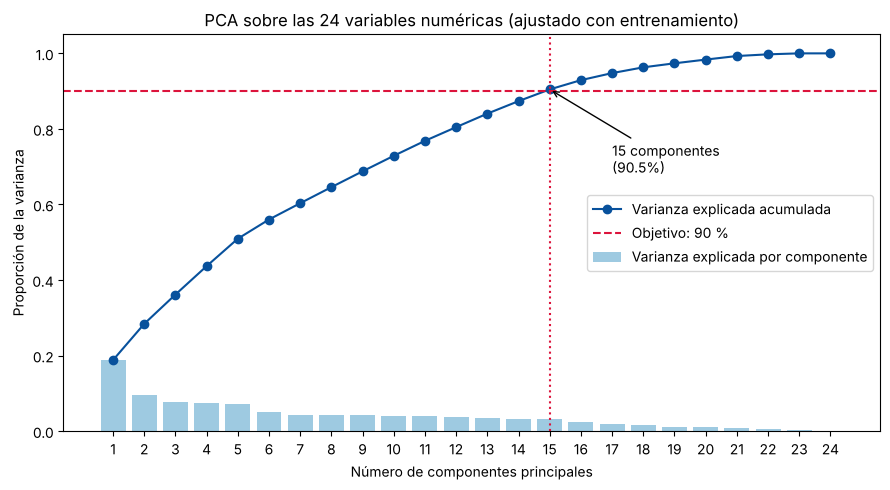

In [9]:
fig, eje = plt.subplots(figsize=(9, 5))
x = np.arange(1, len(var_explicada) + 1)
eje.bar(x, var_explicada, color='#9ecae1', label='Varianza explicada por componente')
eje.plot(x, var_acumulada, marker='o', color='#08519c', label='Varianza explicada acumulada')
eje.axhline(VARIANZA_OBJETIVO, color='crimson', linestyle='--', label='Objetivo: 90 %')
eje.axvline(n_componentes_90, color='crimson', linestyle=':')
eje.annotate(f'{n_componentes_90} componentes\n({var_acumulada[n_componentes_90 - 1]:.1%})',
             xy=(n_componentes_90, var_acumulada[n_componentes_90 - 1]),
             xytext=(n_componentes_90 + 2, var_acumulada[n_componentes_90 - 1] - 0.22),
             arrowprops=dict(arrowstyle='->'))
eje.set_xlabel('Número de componentes principales')
eje.set_ylabel('Proporción de la varianza')
eje.set_title('PCA sobre las 24 variables numéricas (ajustado con entrenamiento)')
eje.set_xticks(x)
eje.set_ylim(0, 1.05)
eje.legend(loc='center right')
fig.tight_layout()
fig.savefig(RUTA_FIGURAS / 'pca_varianza_explicada.png', dpi=150)
plt.show()

In [10]:
texto_pca = (
    f'Las {Z_train.shape[1]} variables numéricas se resumen en **{n_componentes_90} componentes** '
    f'para conservar al menos el {VARIANZA_OBJETIVO:.0%} de la varianza '
    f'(acumulada real: {var_acumulada[n_componentes_90 - 1]:.2%}). '
    f'La primera componente explica {var_explicada[0]:.1%} y las tres primeras '
    f'{var_acumulada[2]:.1%}; es decir, la información está repartida entre muchas componentes '
    f'y no se concentra en una o dos. Reducir de {Z_train.shape[1]} a {n_componentes_90} variables '
    f'numéricas descarta {1 - var_acumulada[n_componentes_90 - 1]:.1%} de la variación.'
)
display(Markdown('**Lectura de la gráfica.** ' + texto_pca))

**Lectura de la gráfica.** Las 24 variables numéricas se resumen en **15 componentes** para conservar al menos el 90% de la varianza (acumulada real: 90.46%). La primera componente explica 18.8% y las tres primeras 36.1%; es decir, la información está repartida entre muchas componentes y no se concentra en una o dos. Reducir de 24 a 15 variables numéricas descarta 9.5% de la variación.

## 8. Entrenamiento de los cuatro modelos

### Regresión logística, `C` y regularización

La regresión logística estima la **probabilidad** de que un pedido llegue tarde. Con umbral 0,50, si la probabilidad es ≥ 0,50 predice "tardío".

La **regularización** penaliza que los coeficientes del modelo crezcan demasiado, lo que ayuda a evitar el sobreajuste (que el modelo memorice el entrenamiento y generalice mal). En scikit-learn, `C` es el **inverso** de la fuerza de regularización:

* `C` **pequeño** (0,1) → regularización **fuerte** → modelo más simple y "contenido".
* `C` **grande** (10) → regularización **débil** → el modelo se ajusta con más libertad a los datos de entrenamiento.

### Diseño de los cuatro modelos

| Modelo | Transformación numérica | C |
|---|---|---:|
| A | Imputación + escalado (sin PCA) | 1,0 |
| B | Imputación + escalado + PCA 90 % | 1,0 |
| C | Imputación + escalado + PCA 90 % | 0,1 |
| D | Imputación + escalado + PCA 90 % | 10,0 |

Todos usan `class_weight='balanced'` (compensa que solo ~7 % de los pedidos son tardíos), las mismas variables categóricas con One-Hot, la misma partición y el mismo umbral. **Lo único que cambia entre modelos es PCA y `C`**, así que cualquier diferencia se puede atribuir a eso.

In [11]:
def construir_modelo(usar_pca, C):
    """Pipeline completo: preprocesamiento + regresión logística.

    Todo lo que aprende (medianas, medias, desviaciones, PCA, categorías) se
    ajusta al llamar a .fit() con datos de entrenamiento únicamente."""
    pasos_numericos = [SimpleImputer(strategy='median'), StandardScaler()]
    if usar_pca:
        # n_components=0.90 -> el menor número de componentes con >= 90 % de varianza
        pasos_numericos.append(PCA(n_components=VARIANZA_OBJETIVO, svd_solver='full',
                                   random_state=SEMILLA))
    preprocesamiento = ColumnTransformer([
        ('numericas', make_pipeline(*pasos_numericos), columnas_numericas),
        ('categoricas', make_pipeline(SimpleImputer(strategy='most_frequent'),
                                     OneHotEncoder(handle_unknown='ignore')),
         columnas_categoricas),
    ])
    return make_pipeline(
        preprocesamiento,
        LogisticRegression(C=C, class_weight='balanced', max_iter=1000,
                           random_state=SEMILLA))


CONFIGURACIONES = [
    ('A', 'Sin PCA', False, 1.0),
    ('B', 'PCA 90 %', True, 1.0),
    ('C', 'PCA 90 %', True, 0.1),
    ('D', 'PCA 90 %', True, 10.0),
]

modelos, probabilidades, predicciones, info_modelos = {}, {}, {}, []
for nombre, transformacion, usar_pca, C in CONFIGURACIONES:
    modelo = construir_modelo(usar_pca, C)
    modelo.fit(X_train, y_train)                         # ajuste SOLO con entrenamiento
    proba = modelo.predict_proba(X_valid)[:, 1]          # P(tardío) en validación
    pred = (proba >= UMBRAL).astype(int)                 # mismo umbral para todos
    assert np.array_equal(pred, modelo.predict(X_valid))
    n_iter = int(modelo[-1].n_iter_[0])
    assert n_iter < 1000, f'El modelo {nombre} no convergió.'

    n_pca = (modelo[0].named_transformers_['numericas'][-1].n_components_
             if usar_pca else np.nan)
    modelos[nombre], probabilidades[nombre], predicciones[nombre] = modelo, proba, pred
    info_modelos.append({'modelo': nombre, 'transformacion': transformacion, 'C': C,
                         'componentes_pca': n_pca,
                         'variables_entrada_logistica': int(modelo[-1].coef_.shape[1]),
                         'iteraciones': n_iter})

display(pd.DataFrame(info_modelos).set_index('modelo'))
print('Los cuatro modelos se entrenaron y convergieron.')

,transformacion,C,componentes_pca,variables_entrada_logistica,iteraciones
modelo,,,,,
A,Sin PCA,1.0,NaN,151,128
B,PCA 90 %,1.0,15.0,142,179
C,PCA 90 %,0.1,15.0,142,82
D,PCA 90 %,10.0,15.0,142,242


Los cuatro modelos se entrenaron y convergieron.


## 9. Evaluación de métricas (validación, umbral 0,50)

* **Accuracy:** proporción total de aciertos.
* **Precision:** de los pedidos que el modelo marcó como tardíos, ¿cuántos realmente lo eran?
* **Recall:** de los pedidos que realmente llegaron tarde, ¿cuántos detectó el modelo?
* **F1-score:** promedio armónico de Precision y Recall (penaliza que uno sea muy bajo).
* **Average Precision (AP):** resume la relación Precision–Recall **para todos los umbrales** posibles, usando las probabilidades; no depende del umbral 0,50. Como referencia, un modelo sin información tendría un AP cercano a la tasa de tardíos (~0,07).

Se agrega ROC-AUC solo como dato complementario.

In [12]:
filas = []
for (nombre, transformacion, usar_pca, C), info in zip(CONFIGURACIONES, info_modelos):
    pred, proba = predicciones[nombre], probabilidades[nombre]
    filas.append({
        'modelo': nombre, 'transformacion': transformacion, 'C': C,
        'componentes_pca': info['componentes_pca'],
        'variables_entrada_logistica': info['variables_entrada_logistica'],
        'accuracy': accuracy_score(y_valid, pred),
        'precision': precision_score(y_valid, pred, zero_division=0),
        'recall': recall_score(y_valid, pred, zero_division=0),
        'f1': f1_score(y_valid, pred, zero_division=0),
        'average_precision': average_precision_score(y_valid, proba),
        'roc_auc': roc_auc_score(y_valid, proba),
    })
resultados = pd.DataFrame(filas).set_index('modelo')

# Referencia (NO es uno de los cuatro modelos): nunca alertar = predecir siempre "a tiempo".
acc_ref = 1 - y_valid.mean()

display(resultados[['transformacion', 'C', 'accuracy', 'precision', 'recall',
                    'f1', 'average_precision', 'roc_auc']].round(4))
print(f'Referencia "nunca alertar": accuracy = {acc_ref:.4f}, recall = 0.0000 '
      '(acierta casi siempre, pero no detecta ninguna entrega tardía).')

,transformacion,C,accuracy,precision,recall,f1,average_precision,roc_auc
modelo,,,,,,,,
A,Sin PCA,1.0,0.6573,0.1193,0.6348,0.2008,0.1462,0.7019
B,PCA 90 %,1.0,0.6419,0.1100,0.6039,0.1861,0.1230,0.6568
C,PCA 90 %,0.1,0.6400,0.1099,0.6067,0.1860,0.1236,0.6580
D,PCA 90 %,10.0,0.6396,0.1090,0.6011,0.1845,0.1226,0.6565


Referencia "nunca alertar": accuracy = 0.9322, recall = 0.0000 (acierta casi siempre, pero no detecta ninguna entrega tardía).


## 10. Matrices de confusión

Cada pedido de validación cae en una de cuatro casillas:

|  | Predicho: a tiempo | Predicho: tardío |
|---|---|---|
| **Real: a tiempo** | TN (verdadero negativo) | **FP** (falso positivo) |
| **Real: tardío** | **FN** (falso negativo) | TP (verdadero positivo) |

* **Falso positivo (FP):** el modelo alerta de un retraso que no ocurre → se gastan recursos innecesariamente.
* **Falso negativo (FN):** el modelo no detecta un pedido que sí llegará tarde → se pierde la oportunidad de actuar y el cliente sale perjudicado.

,TN,FP,FN,TP
modelo,,,,
A,3225,1669,130,226
B,3155,1739,141,215
C,3144,1750,140,216
D,3144,1750,142,214


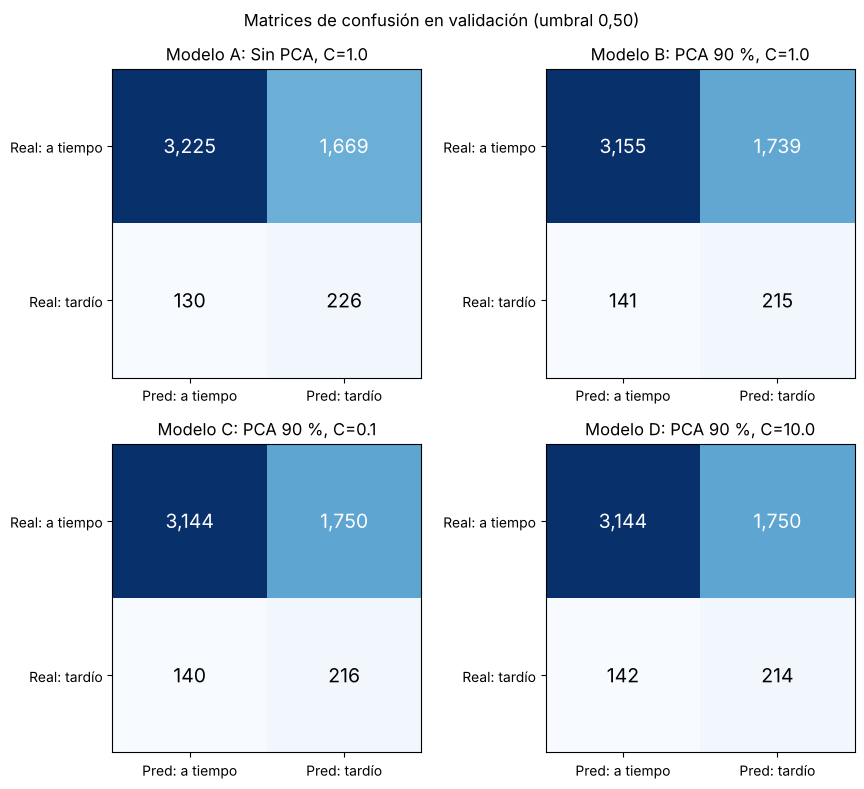

In [13]:
conteos = []
for nombre, *_ in CONFIGURACIONES:
    tn, fp, fn, tp = confusion_matrix(y_valid, predicciones[nombre], labels=[0, 1]).ravel()
    conteos.append({'modelo': nombre, 'TN': int(tn), 'FP': int(fp), 'FN': int(fn), 'TP': int(tp)})
resultados = resultados.join(pd.DataFrame(conteos).set_index('modelo'))
assert (resultados[['TN', 'FP', 'FN', 'TP']].sum(axis=1) == len(y_valid)).all()
display(resultados[['TN', 'FP', 'FN', 'TP']])

fig, ejes = plt.subplots(2, 2, figsize=(9, 8))
for eje, (nombre, transformacion, _, C) in zip(ejes.ravel(), CONFIGURACIONES):
    fila = resultados.loc[nombre]
    cm = np.array([[fila.TN, fila.FP], [fila.FN, fila.TP]])
    eje.imshow(cm, cmap='Blues')
    for i in range(2):
        for j in range(2):
            eje.text(j, i, f'{cm[i, j]:,}', ha='center', va='center', fontsize=14,
                     color='white' if cm[i, j] > cm.max() / 2 else 'black')
    eje.set_xticks([0, 1]); eje.set_xticklabels(['Pred: a tiempo', 'Pred: tardío'])
    eje.set_yticks([0, 1]); eje.set_yticklabels(['Real: a tiempo', 'Real: tardío'])
    eje.set_title(f'Modelo {nombre}: {transformacion}, C={C}')
fig.suptitle('Matrices de confusión en validación (umbral 0,50)')
fig.tight_layout()
fig.savefig(RUTA_FIGURAS / 'matrices_confusion.png', dpi=150)
plt.show()

## 11. Costos empresariales

Cada tipo de error tiene un costo distinto. Se usan estos **costos didácticos**:

* Falso positivo: **R$ 8**
* Falso negativo: **R$ 35**

$$\text{Costo} = 8 \times FP + 35 \times FN$$

> **Aviso importante:** R$ 8 y R$ 35 son **supuestos académicos** del ejercicio. **No** son cifras reales de Olist.

El costo permite comparar modelos por su impacto económico y no solo por una métrica estadística. Un modelo con Accuracy alta puede ser caro si comete muchos errores del tipo más costoso, por eso **no se elige automáticamente el modelo con mayor Accuracy**.

,TN,FP,FN,TP,costo_fp_brl,costo_fn_brl,costo_total_brl
modelo,,,,,,,
A,3225,1669,130,226,13352,4550,17902
B,3155,1739,141,215,13912,4935,18847
C,3144,1750,140,216,14000,4900,18900
D,3144,1750,142,214,14000,4970,18970


Referencia "nunca alertar": FP = 0, FN = 356, costo = R$ 12,460
Menor costo en validación: modelo A (R$ 17,902) | mayor Accuracy: modelo A


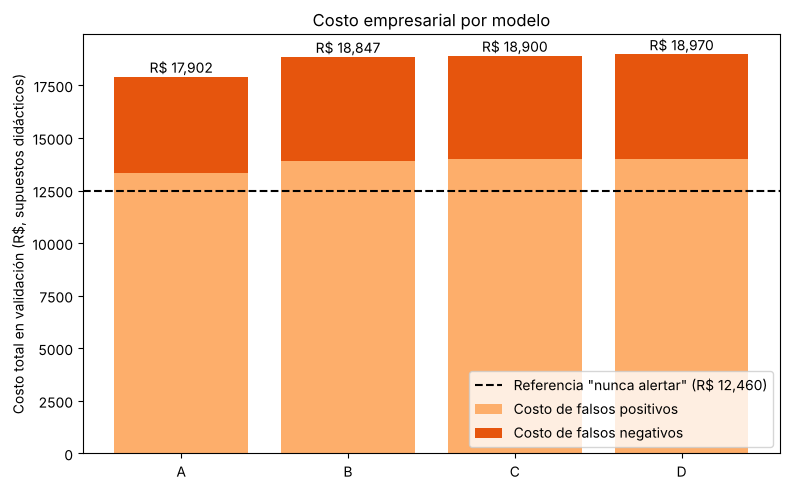

In [14]:
resultados['costo_fp_brl'] = COSTO_FP * resultados['FP']
resultados['costo_fn_brl'] = COSTO_FN * resultados['FN']
resultados['costo_total_brl'] = resultados['costo_fp_brl'] + resultados['costo_fn_brl']

# Referencia: sin modelo (nunca alertar) -> todos los tardíos son falsos negativos.
costo_referencia = COSTO_FN * int(y_valid.sum())

display(resultados[['TN', 'FP', 'FN', 'TP', 'costo_fp_brl', 'costo_fn_brl',
                    'costo_total_brl']])
print(f'Referencia "nunca alertar": FP = 0, FN = {int(y_valid.sum())}, '
      f'costo = R$ {costo_referencia:,.0f}')

mejor_costo = resultados['costo_total_brl'].idxmin()
mejor_accuracy = resultados['accuracy'].idxmax()
print(f'Menor costo en validación: modelo {mejor_costo} '
      f'(R$ {resultados.loc[mejor_costo, "costo_total_brl"]:,.0f}) | '
      f'mayor Accuracy: modelo {mejor_accuracy}')

fig, eje = plt.subplots(figsize=(8, 5))
eje.bar(resultados.index, resultados['costo_fp_brl'], color='#fdae6b', label='Costo de falsos positivos')
eje.bar(resultados.index, resultados['costo_fn_brl'], bottom=resultados['costo_fp_brl'],
        color='#e6550d', label='Costo de falsos negativos')
eje.axhline(costo_referencia, color='black', linestyle='--',
            label=f'Referencia "nunca alertar" (R$ {costo_referencia:,.0f})')
for i, (nombre, total) in enumerate(resultados['costo_total_brl'].items()):
    eje.text(i, total + 200, f'R$ {total:,.0f}', ha='center')
eje.set_ylabel('Costo total en validación (R$, supuestos didácticos)')
eje.set_title('Costo empresarial por modelo')
eje.legend(loc='lower right')
fig.tight_layout()
fig.savefig(RUTA_FIGURAS / 'costos_por_modelo.png', dpi=150)
plt.show()

## 12. Prueba de Kolmogorov-Smirnov (KS) para `valor_flete`

### ¿Qué se quiere comprobar?

Entrenamos con una partición y evaluamos con otra. Conviene verificar que ambas "se parecen". Aquí se compara **una** variable, `valor_flete` (el valor del flete del pedido), entre entrenamiento y validación con `scipy.stats.ks_2samp`.

### Cómo funciona

La prueba KS de dos muestras compara las **funciones de distribución acumulada empíricas (ECDF)** de ambos grupos. El **estadístico D** es la mayor distancia vertical entre las dos curvas (va de 0 a 1): D pequeño → curvas parecidas.

* **Hipótesis nula (H0):** `valor_flete` en entrenamiento y en validación proviene de la misma distribución.
* **Hipótesis alternativa (H1):** las distribuciones son diferentes.
* **Valor p:** probabilidad de observar una diferencia (D) al menos tan grande como la observada **si H0 fuera cierta**.
* **Regla de decisión** con nivel de significancia α = 0,05: si p < 0,05 se rechaza H0; si p ≥ 0,05 **no se rechaza** H0.

> "No rechazar H0" significa que **no hay evidencia suficiente de diferencia**; **no demuestra** que las distribuciones sean iguales.

Prueba KS de dos muestras sobre valor_flete (entrenamiento vs. validación)
  n entrenamiento = 24,500 | n validación = 5,250
  Estadístico D   = 0.0098
  Valor p         = 0.7999
  Nivel de significancia = 0.05
  Decisión: No se rechaza H0


,entrenamiento,validación
count,24500.00,5250.00
mean,22.84,22.38
std,21.09,18.72
min,0.00,0.00
25%,13.87,13.90
50%,17.26,17.13
75%,23.98,23.70
max,711.33,340.40


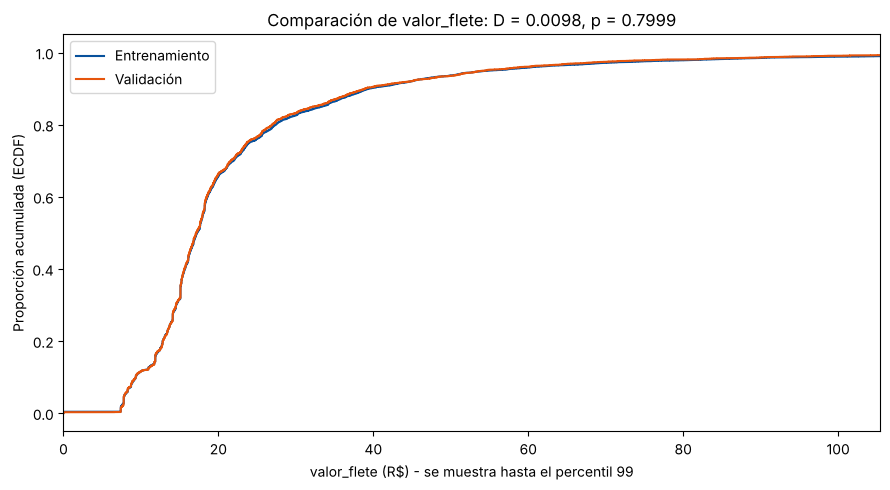

In [15]:
flete_train = train['valor_flete']
flete_valid = valid['valor_flete']

resultado_ks = ks_2samp(flete_train, flete_valid)
D_ks = float(resultado_ks.statistic)
p_ks = float(resultado_ks.pvalue)
decision_ks = 'Se rechaza H0' if p_ks < ALFA else 'No se rechaza H0'

print('Prueba KS de dos muestras sobre valor_flete (entrenamiento vs. validación)')
print(f'  n entrenamiento = {len(flete_train):,} | n validación = {len(flete_valid):,}')
print(f'  Estadístico D   = {D_ks:.4f}')
print(f'  Valor p         = {p_ks:.4f}')
print(f'  Nivel de significancia = {ALFA}')
print(f'  Decisión: {decision_ks}')

display(pd.DataFrame({'entrenamiento': flete_train.describe(),
                      'validación': flete_valid.describe()}).round(2))

# Visualización: ECDF de ambos grupos (D = máxima distancia vertical)
fig, eje = plt.subplots(figsize=(9, 5))
for datos, etiqueta, color in [(flete_train, 'Entrenamiento', '#08519c'),
                               (flete_valid, 'Validación', '#e6550d')]:
    ordenado = np.sort(datos.values)
    eje.step(ordenado, np.arange(1, len(ordenado) + 1) / len(ordenado),
             where='post', label=etiqueta, color=color)
eje.set_xlim(0, flete_train.quantile(0.99))
eje.set_xlabel('valor_flete (R$) - se muestra hasta el percentil 99')
eje.set_ylabel('Proporción acumulada (ECDF)')
eje.set_title(f'Comparación de valor_flete: D = {D_ks:.4f}, p = {p_ks:.4f}')
eje.legend()
fig.tight_layout()
fig.savefig(RUTA_FIGURAS / 'ks_valor_flete_ecdf.png', dpi=150)
plt.show()

In [16]:
if p_ks < ALFA:
    lectura_ks = (f'Como p = {p_ks:.4f} es menor que {ALFA}, **se rechaza H0**: hay evidencia '
                  'estadística de que `valor_flete` se distribuye de forma distinta en '
                  'entrenamiento y validación. Conviene revisar la partición, aunque con '
                  'particiones aleatorias un rechazo también puede ocurrir por azar '
                  f'(aprox. {ALFA:.0%} de las veces aun si las distribuciones fueran iguales).')
else:
    lectura_ks = (f'Como p = {p_ks:.4f} es mayor o igual que {ALFA}, **no se rechaza H0**: no hay '
                  'evidencia suficiente para afirmar que `valor_flete` se distribuya distinto en '
                  f'entrenamiento y validación. La mayor distancia entre las curvas es D = {D_ks:.4f} '
                  f'(unos {100 * D_ks:.2f} puntos porcentuales de proporción acumulada), una diferencia '
                  'compatible con la variación esperada por azar. Esto **no demuestra** que las '
                  'distribuciones sean idénticas: solo que esta prueba no detectó diferencias.')

texto_ks = f'''
| Elemento | Valor |
|---|---|
| Variable comparada | `valor_flete` (entrenamiento vs. validación) |
| Prueba | `scipy.stats.ks_2samp` (dos muestras) |
| H0 | Ambas muestras provienen de la misma distribución |
| H1 | Las distribuciones son diferentes |
| Estadístico D | {D_ks:.4f} |
| Valor p | {p_ks:.4f} |
| Nivel de significancia (α) | {ALFA} |
| Decisión | **{decision_ks}** |

**Interpretación.** {lectura_ks}

**Limitaciones metodológicas.**

1. La prueba compara **solo una variable** (`valor_flete`); no garantiza que las particiones se parezcan en las demás variables ni en la relación entre variables (distribución conjunta).
2. `valor_flete` tiene muchos valores repetidos (empates) y una cola larga con valores extremos; el valor p de KS está pensado para variables continuas, por lo que con empates es una aproximación.
3. Es una prueba de **significancia**, no de relevancia práctica: con muestras grandes puede detectar diferencias minúsculas, y con muestras pequeñas puede no detectar diferencias importantes. No rechazar H0 no prueba igualdad.
4. Si se repitiera la prueba en muchas variables habría que corregir por comparaciones múltiples: con α = 0,05 se esperaría rechazar H0 por azar en ~5 % de ellas.
'''
display(Markdown(texto_ks))


| Elemento | Valor |
|---|---|
| Variable comparada | `valor_flete` (entrenamiento vs. validación) |
| Prueba | `scipy.stats.ks_2samp` (dos muestras) |
| H0 | Ambas muestras provienen de la misma distribución |
| H1 | Las distribuciones son diferentes |
| Estadístico D | 0.0098 |
| Valor p | 0.7999 |
| Nivel de significancia (α) | 0.05 |
| Decisión | **No se rechaza H0** |

**Interpretación.** Como p = 0.7999 es mayor o igual que 0.05, **no se rechaza H0**: no hay evidencia suficiente para afirmar que `valor_flete` se distribuya distinto en entrenamiento y validación. La mayor distancia entre las curvas es D = 0.0098 (unos 0.98 puntos porcentuales de proporción acumulada), una diferencia compatible con la variación esperada por azar. Esto **no demuestra** que las distribuciones sean idénticas: solo que esta prueba no detectó diferencias.

**Limitaciones metodológicas.**

1. La prueba compara **solo una variable** (`valor_flete`); no garantiza que las particiones se parezcan en las demás variables ni en la relación entre variables (distribución conjunta).
2. `valor_flete` tiene muchos valores repetidos (empates) y una cola larga con valores extremos; el valor p de KS está pensado para variables continuas, por lo que con empates es una aproximación.
3. Es una prueba de **significancia**, no de relevancia práctica: con muestras grandes puede detectar diferencias minúsculas, y con muestras pequeñas puede no detectar diferencias importantes. No rechazar H0 no prueba igualdad.
4. Si se repitiera la prueba en muchas variables habría que corregir por comparaciones múltiples: con α = 0,05 se esperaría rechazar H0 por azar en ~5 % de ellas.


## 13. Interpretación de resultados

Los textos siguientes se **generan a partir de los números calculados** en este mismo notebook, de modo que siempre coinciden con las tablas.

In [17]:
r = resultados
A = r.loc['A']
pca_modelos = r.loc[['B', 'C', 'D']]
mejor_pca = pca_modelos['average_precision'].idxmax()
barato_pca = pca_modelos['costo_total_brl'].idxmin()
peor_costo = r['costo_total_brl'].idxmax()
costo_B, costo_C, costo_D = (r.loc[m, 'costo_total_brl'] for m in 'BCD')
rango_C = max(costo_B, costo_C, costo_D) - min(costo_B, costo_C, costo_D)
pct_C = 100 * rango_C / costo_B
sube = lambda v: 'aumenta' if v > 0 else 'disminuye'

# --- Métricas -----------------------------------------------------------------
p_metricas = (
    f'**Modelo A (sin PCA, C=1).** Accuracy {A.accuracy:.3f}, Precision {A.precision:.3f}, '
    f'Recall {A.recall:.3f}, F1 {A.f1:.3f}, Average Precision {A.average_precision:.3f}. '
    f'Detecta {A.TP:,.0f} de {A.TP + A.FN:,.0f} entregas tardías, pero de cada 100 alertas solo '
    f'{100 * A.precision:.0f} son realmente tardías (Precision baja): `class_weight=\'balanced\'` '
    'empuja al modelo a priorizar el Recall a costa de muchas falsas alarmas.\n\n'
    f'**Modelos con PCA (B, C, D).** Recall entre {pca_modelos.recall.min():.3f} y '
    f'{pca_modelos.recall.max():.3f}; F1 entre {pca_modelos.f1.min():.3f} y {pca_modelos.f1.max():.3f}; '
    f'Average Precision entre {pca_modelos.average_precision.min():.3f} y '
    f'{pca_modelos.average_precision.max():.3f}. Frente al modelo A, el mejor de ellos en AP '
    f'({mejor_pca}) {sube(r.loc[mejor_pca, "average_precision"] - A.average_precision)} el AP en '
    f'{abs(r.loc[mejor_pca, "average_precision"] - A.average_precision):.3f} y '
    f'{sube(r.loc[mejor_pca, "recall"] - A.recall)} el Recall en '
    f'{abs(r.loc[mejor_pca, "recall"] - A.recall):.3f}.'
)

# --- Efecto de C ----------------------------------------------------------------
if pct_C < 2:
    cierre_C = ('La diferencia es pequeña: con ~24.500 pedidos de entrenamiento y pocas variables '
                'de entrada, el modelo tiene poco riesgo de sobreajuste, así que endurecer o relajar '
                'la regularización cambia poco el resultado. Los tres modelos con PCA son, en la '
                'práctica, equivalentes.')
else:
    cierre_C = ('La diferencia es apreciable: la regularización sí está cambiando el comportamiento '
                'del modelo en validación.')
p_C = (
    f'**Efecto de `C` (modelos B, C y D).** Con PCA, el costo va de R$ {min(costo_B, costo_C, costo_D):,.0f} '
    f'a R$ {max(costo_B, costo_C, costo_D):,.0f}, un rango de R$ {rango_C:,.0f} '
    f'({pct_C:.1f} % del costo de B). {cierre_C}'
)

# --- PCA ayudó o no ------------------------------------------------------------
metricas_comp = ['accuracy', 'recall', 'f1', 'average_precision']
if all(A[m] >= pca_modelos[m].max() for m in metricas_comp):
    frase_mejor_A = ' y A también tiene mayor Accuracy, Recall, F1 y AP'
else:
    frase_mejor_A = ''
if pca_modelos['costo_total_brl'].min() >= A.costo_total_brl:
    p_pca = (
        f'**¿Ayudó PCA?** En esta ejecución **no**: ninguna configuración con PCA supera al modelo A en '
        f'costo (el mejor con PCA, {barato_pca}, cuesta R$ {pca_modelos.costo_total_brl.min():,.0f} frente a '
        f'R$ {A.costo_total_brl:,.0f} de A){frase_mejor_A}. Una explicación '
        f'plausible (no comprobada aquí) es que PCA descarta {1 - var_acumulada[n_componentes_90 - 1]:.1%} de '
        'la variación numérica y esa parte descartada contiene algo de señal útil para predecir retrasos, '
        'porque PCA ordena por variación y no por capacidad predictiva. Además, con solo 24 variables '
        'numéricas la regresión logística no necesita comprimirlas: PCA aporta poco beneficio de eficiencia '
        f'(de {A.variables_entrada_logistica:.0f} a {r.loc["B", "variables_entrada_logistica"]:.0f} entradas al modelo) '
        'y cuesta en interpretabilidad, porque las componentes mezclan variables originales.'
    )
else:
    p_pca = (
        f'**¿Ayudó PCA?** Sí en costo: el modelo {barato_pca} (R$ {pca_modelos.costo_total_brl.min():,.0f}) '
        f'supera al modelo A (R$ {A.costo_total_brl:,.0f}). Aun así, conviene revisar si la mejora es '
        'relevante frente a la variabilidad de usar una sola partición de validación.'
    )

# --- Accuracy engañosa ---------------------------------------------------------
p_acc = (
    f'**Accuracy no basta.** La referencia "nunca alertar" tendría Accuracy {acc_ref:.3f}, más alta que '
    f'la de cualquiera de los cuatro modelos ({r.accuracy.min():.3f} a {r.accuracy.max():.3f}), pero Recall 0: '
    'no detectaría ninguna entrega tardía. Por eso la decisión se apoya en Recall, F1, AP y, sobre todo, '
    'en el costo.'
)

# --- Costos y selección ---------------------------------------------------------
M = r.loc[mejor_costo]
share_fp = 100 * M.costo_fp_brl / M.costo_total_brl
coincide = ('En esta ejecución el modelo de menor costo también es el de mayor Accuracy, pero eso es '
            'una coincidencia: el criterio de decisión es el costo, no la Accuracy.'
            if mejor_costo == mejor_accuracy else
            f'El modelo de mayor Accuracy ({mejor_accuracy}) **no** es el de menor costo, por lo que '
            'seleccionar por Accuracy habría sido un error.')
if costo_referencia < r.costo_total_brl.min():
    p_ref = (f'**Advertencia sobre el valor del modelo.** Con estos costos didácticos y umbral 0,50, ninguna '
             f'configuración supera a la referencia de "no alertar nunca" (R$ {costo_referencia:,.0f}): '
             f'el costo de las {M.FP:,.0f} falsas alarmas del modelo {mejor_costo} '
             f'(R$ {M.costo_fp_brl:,.0f}) pesa más que el ahorro por detectar {M.TP:,.0f} entregas tardías. '
             'Esto no dice que el modelo sea inútil (tiene capacidad de ordenar pedidos por riesgo: '
             f'ROC-AUC {M.roc_auc:.3f}), sino que el **umbral 0,50 con pesos balanceados genera demasiadas '
             'falsas alarmas** para estos costos. Ajustar el umbral (con datos de validación) sería el '
             'siguiente paso natural; queda fuera de esta actividad, que fija el umbral en 0,50.')
else:
    p_ref = (f'**Valor del modelo.** El modelo {mejor_costo} cuesta R$ {M.costo_total_brl:,.0f}, menos que '
             f'la referencia de "no alertar nunca" (R$ {costo_referencia:,.0f}).')

p_seleccion = (
    f'**Modelo seleccionado: {mejor_costo}** ({M.transformacion}, C={M.C}). Es el de menor costo en validación '
    f'(R$ {M.costo_total_brl:,.0f}; el más caro, {peor_costo}, cuesta R$ {r.loc[peor_costo, "costo_total_brl"]:,.0f}). '
    f'Sus errores se reparten así: {M.FP:,.0f} falsos positivos (R$ {M.costo_fp_brl:,.0f}, {share_fp:.0f} % del '
    f'costo) y {M.FN:,.0f} falsos negativos (R$ {M.costo_fn_brl:,.0f}). Aunque cada falso negativo cuesta '
    f'{COSTO_FN / COSTO_FP:.2f} veces más que un falso positivo, el volumen de falsos positivos domina el costo. '
    f'{coincide} Los costos son supuestos académicos y la comparación se hizo con una sola partición de '
    'validación, sin intervalos de incertidumbre.'
)

texto_interpretacion = '\n\n'.join([p_metricas, p_C, p_pca, p_acc, p_ref, p_seleccion])
display(Markdown(texto_interpretacion))

**Modelo A (sin PCA, C=1).** Accuracy 0.657, Precision 0.119, Recall 0.635, F1 0.201, Average Precision 0.146. Detecta 226 de 356 entregas tardías, pero de cada 100 alertas solo 12 son realmente tardías (Precision baja): `class_weight='balanced'` empuja al modelo a priorizar el Recall a costa de muchas falsas alarmas.

**Modelos con PCA (B, C, D).** Recall entre 0.601 y 0.607; F1 entre 0.184 y 0.186; Average Precision entre 0.123 y 0.124. Frente al modelo A, el mejor de ellos en AP (C) disminuye el AP en 0.023 y disminuye el Recall en 0.028.

**Efecto de `C` (modelos B, C y D).** Con PCA, el costo va de R$ 18,847 a R$ 18,970, un rango de R$ 123 (0.7 % del costo de B). La diferencia es pequeña: con ~24.500 pedidos de entrenamiento y pocas variables de entrada, el modelo tiene poco riesgo de sobreajuste, así que endurecer o relajar la regularización cambia poco el resultado. Los tres modelos con PCA son, en la práctica, equivalentes.

**¿Ayudó PCA?** En esta ejecución **no**: ninguna configuración con PCA supera al modelo A en costo (el mejor con PCA, B, cuesta R$ 18,847 frente a R$ 17,902 de A) y A también tiene mayor Accuracy, Recall, F1 y AP. Una explicación plausible (no comprobada aquí) es que PCA descarta 9.5% de la variación numérica y esa parte descartada contiene algo de señal útil para predecir retrasos, porque PCA ordena por variación y no por capacidad predictiva. Además, con solo 24 variables numéricas la regresión logística no necesita comprimirlas: PCA aporta poco beneficio de eficiencia (de 151 a 142 entradas al modelo) y cuesta en interpretabilidad, porque las componentes mezclan variables originales.

**Accuracy no basta.** La referencia "nunca alertar" tendría Accuracy 0.932, más alta que la de cualquiera de los cuatro modelos (0.640 a 0.657), pero Recall 0: no detectaría ninguna entrega tardía. Por eso la decisión se apoya en Recall, F1, AP y, sobre todo, en el costo.

**Advertencia sobre el valor del modelo.** Con estos costos didácticos y umbral 0,50, ninguna configuración supera a la referencia de "no alertar nunca" (R$ 12,460): el costo de las 1,669 falsas alarmas del modelo A (R$ 13,352) pesa más que el ahorro por detectar 226 entregas tardías. Esto no dice que el modelo sea inútil (tiene capacidad de ordenar pedidos por riesgo: ROC-AUC 0.702), sino que el **umbral 0,50 con pesos balanceados genera demasiadas falsas alarmas** para estos costos. Ajustar el umbral (con datos de validación) sería el siguiente paso natural; queda fuera de esta actividad, que fija el umbral en 0,50.

**Modelo seleccionado: A** (Sin PCA, C=1.0). Es el de menor costo en validación (R$ 17,902; el más caro, D, cuesta R$ 18,970). Sus errores se reparten así: 1,669 falsos positivos (R$ 13,352, 75 % del costo) y 130 falsos negativos (R$ 4,550). Aunque cada falso negativo cuesta 4.38 veces más que un falso positivo, el volumen de falsos positivos domina el costo. En esta ejecución el modelo de menor costo también es el de mayor Accuracy, pero eso es una coincidencia: el criterio de decisión es el costo, no la Accuracy. Los costos son supuestos académicos y la comparación se hizo con una sola partición de validación, sin intervalos de incertidumbre.

## 14. Conclusiones

In [18]:
conclusiones = [
    f'**PCA.** Se necesitan {n_componentes_90} de {Z_train.shape[1]} componentes para conservar al menos '
    f'el {VARIANZA_OBJETIVO:.0%} de la varianza numérica (acumulada: {var_acumulada[n_componentes_90 - 1]:.2%}).',
    f'**Comparación de modelos.** Menor costo en validación: modelo {mejor_costo} '
    f'(R$ {M.costo_total_brl:,.0f}); mayor costo: modelo {peor_costo} '
    f'(R$ {r.loc[peor_costo, "costo_total_brl"]:,.0f}).',
    ('**PCA vs. sin PCA.** En esta ejecución PCA no mejoró el costo ni las métricas del modelo base de '
     'la semana 12.' if pca_modelos['costo_total_brl'].min() >= A.costo_total_brl else
     f'**PCA vs. sin PCA.** El modelo {barato_pca} con PCA mejoró el costo frente al modelo base.'),
    f'**Parámetro C.** Entre C = 0,1 y C = 10 (con PCA) el costo varía R$ {rango_C:,.0f} ({pct_C:.1f} %), '
    + ('una diferencia pequeña.' if pct_C < 2 else 'una diferencia apreciable.'),
    f'**Costos.** Con los supuestos didácticos (FP = R$ {COSTO_FP}, FN = R$ {COSTO_FN}) la decisión se '
    'basa en el costo y no en la Accuracy. Referencia "nunca alertar": '
    f'R$ {costo_referencia:,.0f}.',
    f'**Prueba KS.** D = {D_ks:.4f}, p = {p_ks:.4f}, α = {ALFA}: {decision_ks[0].lower() + decision_ks[1:]}. '
    'No se detectó diferencia en `valor_flete` entre entrenamiento y validación, lo que no prueba igualdad '
    'y solo cubre una variable.',
    '**Alcance.** Todo se evaluó en validación; la partición de prueba sigue reservada para la evaluación '
    'final. Los costos son supuestos académicos, no cifras reales de Olist.',
]
texto_conclusiones = '\n'.join(f'{i}. {c}' for i, c in enumerate(conclusiones, 1))
display(Markdown(texto_conclusiones))

1. **PCA.** Se necesitan 15 de 24 componentes para conservar al menos el 90% de la varianza numérica (acumulada: 90.46%).
2. **Comparación de modelos.** Menor costo en validación: modelo A (R$ 17,902); mayor costo: modelo D (R$ 18,970).
3. **PCA vs. sin PCA.** En esta ejecución PCA no mejoró el costo ni las métricas del modelo base de la semana 12.
4. **Parámetro C.** Entre C = 0,1 y C = 10 (con PCA) el costo varía R$ 123 (0.7 %), una diferencia pequeña.
5. **Costos.** Con los supuestos didácticos (FP = R$ 8, FN = R$ 35) la decisión se basa en el costo y no en la Accuracy. Referencia "nunca alertar": R$ 12,460.
6. **Prueba KS.** D = 0.0098, p = 0.7999, α = 0.05: no se rechaza H0. No se detectó diferencia en `valor_flete` entre entrenamiento y validación, lo que no prueba igualdad y solo cubre una variable.
7. **Alcance.** Todo se evaluó en validación; la partición de prueba sigue reservada para la evaluación final. Los costos son supuestos académicos, no cifras reales de Olist.

## 15. Registro de resultados y autoverificación

Se guardan los resultados reales de este notebook en `reports/resultados_experimentos.csv` y `reports/resumen_analisis.md`, y se ejecutan comprobaciones finales.

In [19]:
# --- CSV con los resultados de los cuatro modelos ------------------------------
csv = resultados.reset_index().rename(columns={
    'modelo': 'modelo', 'transformacion': 'transformacion', 'C': 'C'})
csv.insert(3, 'conjunto_evaluado', 'validacion')
csv.insert(4, 'umbral', UMBRAL)
csv = csv[['modelo', 'transformacion', 'C', 'conjunto_evaluado', 'umbral', 'componentes_pca',
           'variables_entrada_logistica', 'accuracy', 'precision', 'recall', 'f1',
           'average_precision', 'roc_auc', 'TN', 'FP', 'FN', 'TP',
           'costo_fp_brl', 'costo_fn_brl', 'costo_total_brl']]
ruta_csv = RUTA_REPORTES / 'resultados_experimentos.csv'
csv.round(6).to_csv(ruta_csv, index=False, encoding='utf-8')


# --- Resumen en Markdown ---------------------------------------------------------
def tabla_md(df):
    encabezado = '| ' + ' | '.join(df.columns) + ' |'
    separador = '|' + '|'.join(['---'] * len(df.columns)) + '|'
    cuerpo = ['| ' + ' | '.join(str(v) for v in fila) + ' |' for fila in df.itertuples(index=False)]
    return '\n'.join([encabezado, separador] + cuerpo)

t_metricas = resultados.reset_index()[['modelo', 'transformacion', 'C', 'accuracy', 'precision',
                                       'recall', 'f1', 'average_precision']].copy()
for c in ['accuracy', 'precision', 'recall', 'f1', 'average_precision']:
    t_metricas[c] = t_metricas[c].map('{:.4f}'.format)
t_costos = resultados.reset_index()[['modelo', 'TN', 'FP', 'FN', 'TP', 'costo_fp_brl',
                                     'costo_fn_brl', 'costo_total_brl']].copy()
for c in ['TN', 'FP', 'FN', 'TP', 'costo_fp_brl', 'costo_fn_brl', 'costo_total_brl']:
    t_costos[c] = t_costos[c].map('{:,.0f}'.format)

nota_s12 = ''
if s12 is not None:
    m12 = s12['metricas']
    nota_s12 = (
        '\n\n**Nota de reproducibilidad.** El modelo A repite la configuración de la semana 12. '
        f'En el JSON de la semana 12: Accuracy {m12["accuracy"]:.4f}, Recall {m12["recall"]:.4f}, '
        f'F1 {m12["f1"]:.4f}, costo R$ {s12["costo_errores_brl"]:,.0f}. En esta ejecución: '
        f'Accuracy {A.accuracy:.4f}, Recall {A.recall:.4f}, F1 {A.f1:.4f}, costo R$ {A.costo_total_brl:,.0f}. '
        'Las pequeñas diferencias (del orden de una predicción) pueden deberse a versiones distintas de las '
        'librerías numéricas; la muestra y las particiones son idénticas (misma huella).')

resumen = f'''# Resumen de análisis - Semana 14 (Olist ML Challenge, ID 13)

Generado automáticamente por `notebooks/S14_ML_Challenge.ipynb` con los resultados reales de su ejecución.

## 1. Datos y reproducibilidad

- Muestra: {len(muestra):,} pedidos (una fila por pedido), semilla {SEMILLA}, huella `{huella_muestra}`.
- Particiones: entrenamiento {len(train):,} / validación {len(valid):,} / prueba {len(test):,} (la prueba permanece reservada y no se usó).
- Variable objetivo `is_late` (1 = entrega posterior a la fecha estimada); tasa de tardíos en la muestra: {muestra['is_late'].mean():.2%}.
- Preprocesamiento, PCA y escalado ajustados únicamente con entrenamiento. Sin variables posteriores a la entrega.
- Entorno: Python {sys.version.split()[0]}, pandas {pd.__version__}, numpy {np.__version__}, scikit-learn {sklearn.__version__}, scipy {scipy.__version__}.{nota_s12}

## 2. Actividad 1 - PCA

{texto_pca}

Figura: `reports/figures/pca_varianza_explicada.png`.

## 3. Actividad 2 - Cuatro regresiones logísticas (validación, umbral {UMBRAL:.2f}, `class_weight='balanced'`)

{tabla_md(t_metricas)}

## 4. Actividad 3 - Costos empresariales

Costo = {COSTO_FP} x FP + {COSTO_FN} x FN. **Los costos son supuestos académicos; no son cifras reales de Olist.**

{tabla_md(t_costos)}

Referencia "nunca alertar" (sin modelo): costo R$ {costo_referencia:,.0f}.

## 5. Interpretación y selección del modelo

{texto_interpretacion}

## 6. Actividad 4 - Prueba Kolmogorov-Smirnov

{texto_ks}

## 7. Conclusiones

{texto_conclusiones}
'''
ruta_md = RUTA_REPORTES / 'resumen_analisis.md'
ruta_md.write_text(resumen, encoding='utf-8')
print('Archivos generados:')
for ruta in [ruta_csv, ruta_md] + sorted(RUTA_FIGURAS.glob('*.png')):
    print(' -', ruta.relative_to(RAIZ))

Archivos generados:
 - reports/resultados_experimentos.csv
 - reports/resumen_analisis.md
 - reports/figures/costos_por_modelo.png
 - reports/figures/ks_valor_flete_ecdf.png
 - reports/figures/matrices_confusion.png
 - reports/figures/pca_varianza_explicada.png


In [20]:
# --- Autoverificación ------------------------------------------------------------
assert len(muestra) == 35000
assert (len(train), len(valid), len(test)) == (24500, 5250, 5250)
assert set(train['order_id']).isdisjoint(valid['order_id'])
assert set(train['order_id']).isdisjoint(test['order_id'])
assert set(valid['order_id']).isdisjoint(test['order_id'])
assert list(resultados.index) == ['A', 'B', 'C', 'D']
assert all(m[-1].class_weight == 'balanced' for m in modelos.values())
assert [m[-1].C for m in modelos.values()] == [1.0, 1.0, 0.1, 10.0]
assert resultados.loc['A', 'componentes_pca'] != resultados.loc['A', 'componentes_pca']  # NaN: sin PCA
assert (resultados.loc[['B', 'C', 'D'], 'componentes_pca'] == n_componentes_90).all()
assert var_acumulada[n_componentes_90 - 1] >= VARIANZA_OBJETIVO
assert np.allclose(resultados['costo_total_brl'], COSTO_FP * resultados['FP'] + COSTO_FN * resultados['FN'])
assert 0 <= D_ks <= 1 and 0 <= p_ks <= 1
leido = pd.read_csv(ruta_csv)
assert len(leido) == 4 and leido['costo_total_brl'].notna().all()
assert 'Se rechaza' in resumen or 'No se rechaza' in resumen
print('Autoverificación superada.')

Autoverificación superada.
